In [1]:
import numpy as np 
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics

In [2]:
# import requests
# path= 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/drug200.csv'
# response = requests.get(path)
# with open ('drug_data.csv','wb') as file:
#     file.write(response.content)
# print('download successfully')

download successfully


## Load the data

In [3]:
drug_data = pd.read_csv('drug_data.csv')
drug_data.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


## Data Analysis and pre-processing

In [4]:
drug_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [6]:
# we have four feature which is categorical data so we have to converted to numerical
label_encoder = LabelEncoder()
drug_data['Sex'] = label_encoder.fit_transform(drug_data['Sex'])
drug_data['BP'] = label_encoder.fit_transform(drug_data['BP'])
drug_data['Cholesterol'] = label_encoder.fit_transform(drug_data['Cholesterol'])

drug_data

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,drugY
1,47,1,1,0,13.093,drugC
2,47,1,1,0,10.114,drugC
3,28,0,2,0,7.798,drugX
4,61,0,1,0,18.043,drugY
...,...,...,...,...,...,...
195,56,0,1,0,11.567,drugC
196,16,1,1,0,12.006,drugC
197,52,1,2,0,9.894,drugX
198,23,1,2,1,14.020,drugX


In [7]:
drug_data.isnull().sum()

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

In [10]:
drug_data['Drug'].unique()

array(['drugY', 'drugC', 'drugX', 'drugA', 'drugB'], dtype=object)

In [13]:
custome_map = {'drugA' : 0, 'drugB' : 1, 'drugC' : 2, 'drugX' : 3, 'drugY': 5}
drug_data['drug_num'] = drug_data['Drug'].map(custome_map)
drug_data

,Age,Sex,BP,Cholesterol,Na_to_K,Drug,drug_num
0,23,0,0,0,25.355,drugY,5
1,47,1,1,0,13.093,drugC,2
2,47,1,1,0,10.114,drugC,2
3,28,0,2,0,7.798,drugX,3
4,61,0,1,0,18.043,drugY,5
...,...,...,...,...,...,...,...
195,56,0,1,0,11.567,drugC,2
196,16,1,1,0,12.006,drugC,2
197,52,1,2,0,9.894,drugX,3
198,23,1,2,1,14.020,drugX,3


In [14]:
drug_data.drop('Drug',axis=1).corr()['drug_num']

Age           -0.012544
Sex           -0.094742
BP             0.264149
Cholesterol    0.042140
Na_to_K        0.678143
drug_num       1.000000
Name: drug_num, dtype: float64

In [18]:
category_counts = drug_data['Drug'].value_counts()
category_counts

Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64

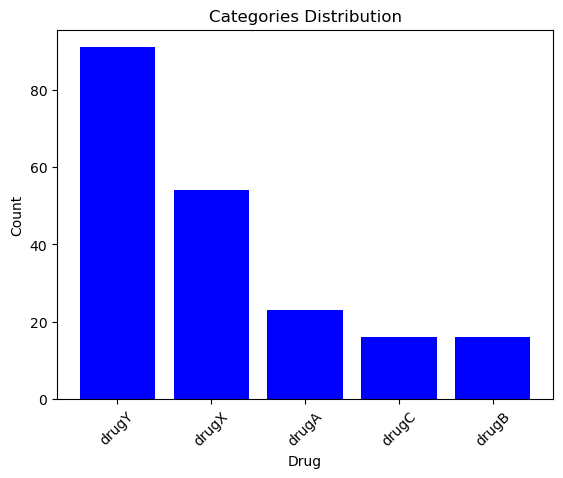

In [20]:
plt.bar(category_counts.index,category_counts.values,color='blue')
plt.xlabel('Drug')
plt.ylabel('Count')
plt.title('Categories Distribution')
plt.xticks(rotation=45)
plt.show()

## Modeling

In [25]:
y = drug_data['Drug']
X = drug_data.drop(['Drug','drug_num'],axis=1)

In [26]:
X_trainset,X_testset,y_trainset,y_testset = train_test_split(X,y,random_state=42,test_size=0.3)

In [27]:
drugTree = DecisionTreeClassifier(criterion="entropy", max_depth = 4)

In [28]:
drugTree.fit(X_trainset,y_trainset)

,criterion,'entropy'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [35]:
tree_predictions = drugTree.predict(X_testset)

In [36]:
print("Decision Trees's Accuracy: ", metrics.accuracy_score(y_testset, tree_predictions))

Decision Trees's Accuracy:  1.0


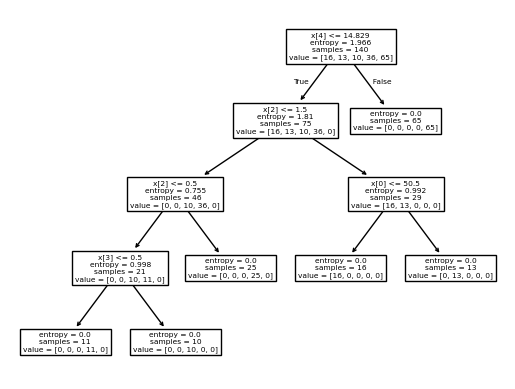

In [38]:
plot_tree(drugTree)
plt.show()

In [40]:
drugTree = DecisionTreeClassifier(criterion="entropy", max_depth = 3)
drugTree.fit(X_trainset,y_trainset)
tree_predictions = drugTree.predict(X_testset)
print("Decision Trees's Accuracy: ", metrics.accuracy_score(y_testset, tree_predictions))

Decision Trees's Accuracy:  0.9


In [37]:
import numpy as np 
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics

drug_data = pd.read_csv('drug_data.csv')

# 1. Map Binary data (Alphabetical order works fine for Sex: F=0, M=1)
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
drug_data['Sex'] = label_encoder.fit_transform(drug_data['Sex'])

# 2. Map Ordinal data explicitly to preserve scale (Low -> Normal -> High)
bp_map = {'LOW': 0, 'NORMAL': 1, 'HIGH': 2}
chol_map = {'NORMAL': 0, 'HIGH': 1}

drug_data['BP'] = drug_data['BP'].map(bp_map)
drug_data['Cholesterol'] = drug_data['Cholesterol'].map(chol_map)

# 3. Split Features and Target
y = drug_data['Drug']
X = drug_data.drop(['Drug'], axis=1) # No need for 'drug_num' if you drop it anyway

# 4. Train and Evaluate
X_trainset, X_testset, y_trainset, y_testset = train_test_split(X, y, random_state=42, test_size=0.3)

drugTree = DecisionTreeClassifier(criterion="entropy", max_depth=4)
drugTree.fit(X_trainset, y_trainset)
tree_predictions = drugTree.predict(X_testset)

print("Decision Trees's Accuracy: ", metrics.accuracy_score(y_testset, tree_predictions))


Decision Trees's Accuracy:  1.0


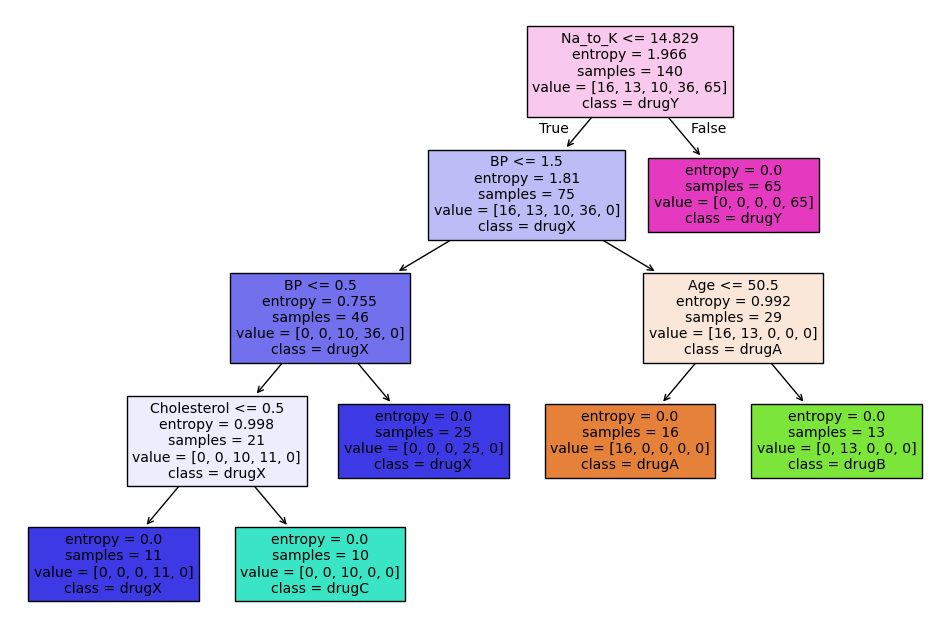

In [39]:
from matplotlib import pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(12,8))
plot_tree(drugTree, feature_names=X.columns, class_names=drugTree.classes_, filled=True)
plt.show()
